In [15]:
# Task 1
train_valid, test = train_test_split(df_encoded, test_size=0.2, random_state=42)

# Task 2
train, valid = train_test_split(train_valid, test_size=0.25, random_state=42)

# Task 3
X_train = train.drop("churn", axis=1)
y_train = train["churn"]

X_valid = valid.drop("churn", axis=1)
y_valid = valid["churn"]

X_test = test.drop("churn", axis=1)
y_test = test["churn"]

# Task 4
print(f"Training set: X={X_train.shape}, y={y_train.shape}")
print(f"Validation set: X={X_valid.shape}, y={y_valid.shape}")
print(f"Test set: X={X_test.shape}, y={y_test.shape}")

Training set: X=(6000, 12), y=(6000,)
Validation set: X=(2000, 12), y=(2000,)
Test set: X=(2000, 12), y=(2000,)


In [12]:
# Task :1
print("Class Counts:\n", df['churn'].value_counts())

# Task :2
print("\nClass Percentages:\n", df['churn'].value_counts(normalize=True) * 100)

# Task :3
def upsample(features, target, repeat):
    features_0 = features[target == 0]
    features_1 = features[target == 1]
    target_0 = target[target == 0]
    target_1 = target[target == 1]
    
    features_up = pd.concat([features_0] + [features_1] * repeat)
    target_up = pd.concat([target_0] + [target_1] * repeat)
    features_up, target_up = shuffle(features_up, target_up, random_state=42)
    
    return features_up, target_up

features = df.drop("churn", axis=1)
target = df["churn"]
features_up, target_up = upsample(features, target, 3)

# Task 4
print("\nClass Counts After Upsampling:\n", target_up.value_counts())

# Task 5
def downsample(features, target, fraction):
    features_0 = features[target == 0].sample(frac=fraction, random_state=42)
    features_1 = features[target == 1]
    target_0 = target[target == 0].sample(frac=fraction, random_state=42)
    target_1 = target[target == 1]
    
    features_down = pd.concat([features_0, features_1])
    target_down = pd.concat([target_0, target_1])
    
    return shuffle(features_down, target_down, random_state=42)

Class Counts:
 churn
0    7963
1    2037
Name: count, dtype: int64

Class Percentages:
 churn
0    79.63
1    20.37
Name: proportion, dtype: float64

Class Counts After Upsampling:
 churn
0    7963
1    6111
Name: count, dtype: int64


In [10]:
# Part 3 Encoding snippet for your columns:
df_encoded = pd.get_dummies(df, columns=['country', 'gender'], drop_first=True)

In [14]:
# Task 1: Identify categorical columns
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print("Categorical Columns:", categorical_cols)

# Task 2: Apply One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=['country', 'gender'], drop_first=True)

# Task 3: Print the dataset head and total columns
print("\nEncoded Dataset Head:")
print(df_encoded.head())
print("\nTotal columns after encoding:", df_encoded.shape[1])

Categorical Columns: ['country', 'gender']

Encoded Dataset Head:
   customer_id  credit_score  age  tenure    balance  products_number  \
0     15634602           619   42       2       0.00                1   
1     15647311           608   41       1   83807.86                1   
2     15619304           502   42       8  159660.80                3   
3     15701354           699   39       1       0.00                2   
4     15737888           850   43       2  125510.82                1   

   credit_card  active_member  estimated_salary  churn  country_Germany  \
0            1              1         101348.88      1            False   
1            0              1         112542.58      0            False   
2            1              0         113931.57      1            False   
3            0              0          93826.63      0            False   
4            1              1          79084.10      0            False   

   country_Spain  gender_Male  
0          F

C:\Users\manah\AppData\Local\Temp\ipykernel_7028\4113106119.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns.tolist()


In [9]:
target_corr = df.corr(numeric_only=True)['churn'].sort_values()
print("Correlation with churn:\n", target_corr)

selected_features = target_corr[(target_corr > 0.1) | (target_corr < -0.1)].index.tolist()
print("\nSelected Features based on correlation threshold (|r| > 0.1):")
print(selected_features)

df_reduced = df.drop(columns=['customer_id'], errors='ignore')
print("\nDataset after dropping customer_id:")
print(df_reduced.head())

Correlation with churn:
 active_member      -0.156128
products_number    -0.047820
credit_score       -0.027094
tenure             -0.014001
credit_card        -0.007138
customer_id        -0.006248
estimated_salary    0.012097
balance             0.118533
age                 0.285323
churn               1.000000
Name: churn, dtype: float64

Selected Features based on correlation threshold (|r| > 0.1):
['active_member', 'balance', 'age', 'churn']

Dataset after dropping customer_id:
   credit_score country  gender  age  tenure    balance  products_number  \
0           619  France  Female   42       2       0.00                1   
1           608   Spain  Female   41       1   83807.86                1   
2           502  France  Female   42       8  159660.80                3   
3           699  France  Female   39       1       0.00                2   
4           850   Spain  Female   43       2  125510.82                1   

   credit_card  active_member  estimated_salary  churn 

In [8]:

print(df.columns.tolist())

['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']


In [7]:
target_corr = df.corr(numeric_only=True)['Exited']
selected_features = target_corr[(target_corr > 0.1) | (target_corr < -0.1)].index.tolist()

print("Selected Features based on correlation threshold:")
print(selected_features)

KeyError: 'Exited'

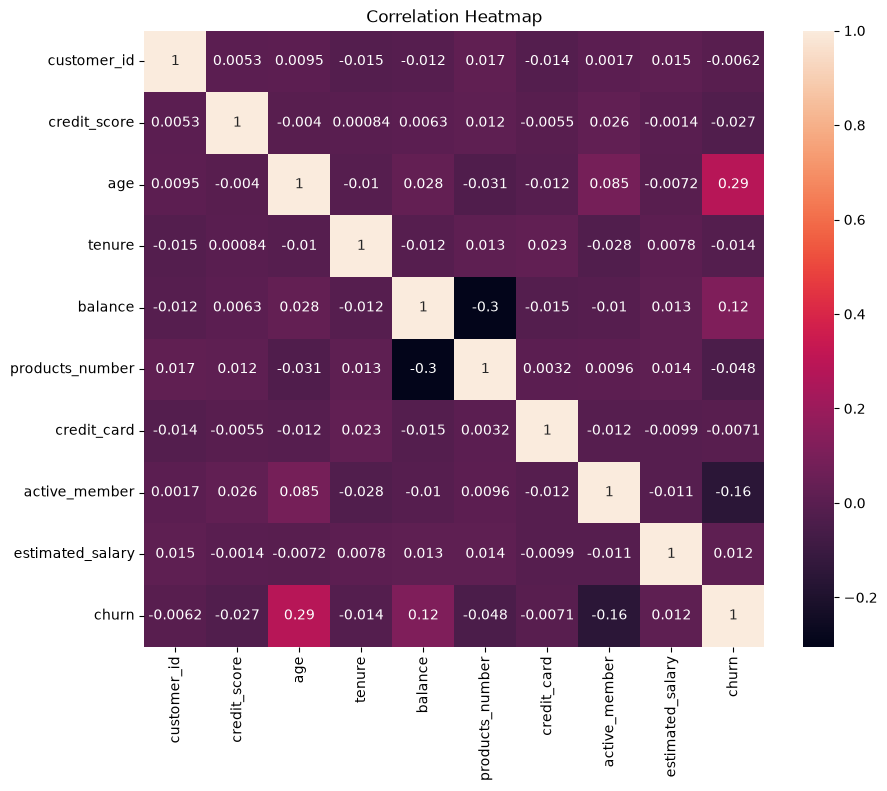

KeyError: 'Exited'

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.title("Correlation Heatmap")
plt.show()

target_correlations = df.corr(numeric_only=True)['Exited'].sort_values()
print(target_correlations)

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
df = pd.read_csv("../dataset/bank_churn.csv")
print(df.head())

   customer_id  credit_score country  gender  age  tenure    balance  \
0     15634602           619  France  Female   42       2       0.00   
1     15647311           608   Spain  Female   41       1   83807.86   
2     15619304           502  France  Female   42       8  159660.80   
3     15701354           699  France  Female   39       1       0.00   
4     15737888           850   Spain  Female   43       2  125510.82   

   products_number  credit_card  active_member  estimated_salary  churn  
0                1            1              1         101348.88      1  
1                1            0              1         112542.58      0  
2                3            1              0         113931.57      1  
3                2            0              0          93826.63      0  
4                1            1              1          79084.10      0  


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

df = pd.read_csv("bank_churn.csv")[cite: 2]
print(df.head())[cite: 2]

ModuleNotFoundError: No module named 'pandas'